# Import Required Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install shap==0.44.0
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 533.5/533.5 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283835 sha256=8d97388ff21b35778e23d9e0a27a3d533ed350a4402f57e739f6b6e0f7750272
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from glob import glob
import seaborn as sns
from PIL import Image
import itertools
import os
import pickle
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.layers import BatchNormalization
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from keras.callbacks import EarlyStopping,ModelCheckpoint
from tensorflow.keras.optimizers.legacy import Adam
from keras.models import Model
from keras.layers import Conv2D, MaxPooling2D, Dense, Input, Activation, Dropout, GlobalAveragePooling2D, \
    BatchNormalization, concatenate, AveragePooling2D
from keras.optimizers import Adam
from keras.utils import plot_model
from keras.applications import VGG16
from keras.applications import ResNet50
from keras.applications.mobilenet import MobileNet
import shap
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import cv2

#Load Data
This the HAM10000 ("Human Against Machine with 10000 training images") dataset.It consists of 10015 dermatoscopicimages which are released as a training set for academic machine learning purposes and are publiclyavailable through the ISIC archive. This benchmark dataset can be used for machine learning and for comparisons with human experts.

It has 7 different classes of skin cancer which are listed below :
1. Melanocytic nevi
2. Melanoma
3. Benign keratosis-like lesions
4. Basal cell carcinoma
5. Actinic keratoses
6. Vascular lesions
7. Dermatofibroma

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Project/archive/HAM10000_metadata.csv")

In [ ]:
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB


#Data Cleaning

In [ ]:
# Check for missing values
df.isnull().sum()

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

The feature age has 57 null values.  This can be filled with the age mean, as deleting 57 records would result in data loss.

In [ ]:
# Fill missing values with mean
df['age'].fillna(int(df['age'].mean()),inplace=True)

In [ ]:
# Path of image folder which is the base folder where all the skin images
base_dir = '/content/drive/MyDrive/Project/archive'

# Merge images from both image folders into one dictionary
image_id_path = {os.path.splitext(os.path.basename(x))[0]: x
                     for x in glob(os.path.join(base_dir, '*', '*.jpg'))}

In [ ]:
# Full form of the skin lesion types
skin_lesion_types = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions ',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}

In [ ]:
df['lesion_type'].value_counts()

Melanocytic nevi                  6705
Melanoma                          1113
Benign keratosis-like lesions     1099
Basal cell carcinoma               514
Actinic keratoses                  327
Vascular lesions                   142
Dermatofibroma                     115
Name: lesion_type, dtype: int64

In [ ]:
# image_path column includes the paths to all the skin_lesion images
df['image_path'] = df['image_id'].map(image_id_path.get)
# lesion_type column includes the different types of skin lesion
df['lesion_type'] = df['dx'].map(skin_lesion_types.get)
# Convert the lesion_type column to category dtype
df['lesion_type'] = df['lesion_type'].astype('category')
# Categorise the lesion_type
df['lesion_type_idx'] = df['lesion_type'].cat.rename_categories([0, 1, 2, 3, 4, 5, 6])
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_type,lesion_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2


In [ ]:
# Check the number of skin images
df.shape[0]

10015

# Exploratory Data Analysis EDA

## Univariate Analysis

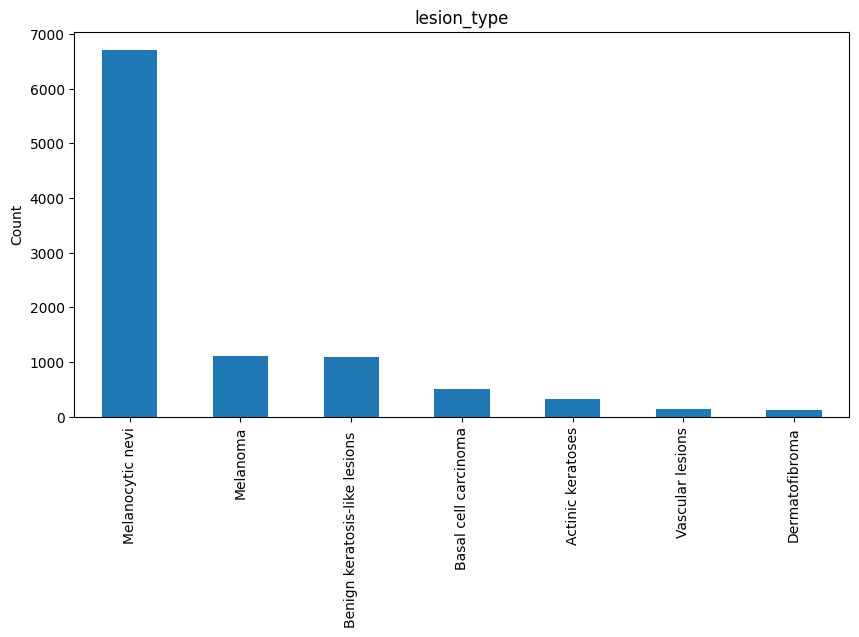

In [ ]:
# Plot the types of skin lesion in the data
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
df['lesion_type'].value_counts().plot(kind='bar', ax=ax1)
plt.ylabel("Count")
plt.title('lesion_type')
plt.show()

From the plot above it can be seen that the lesion_type with the highest number is the "Melanocytic nevi" and the least is the "Dermatofibroma". This shows that we have an imbalanced data


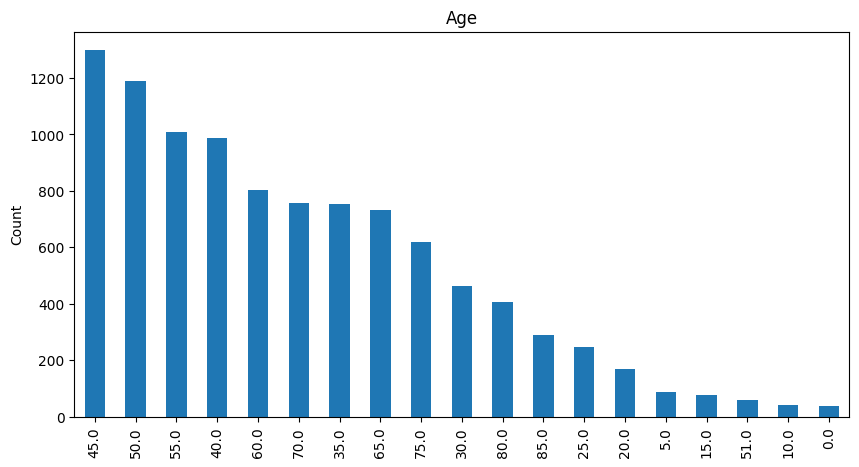

In [ ]:
# Plot the age range of the diagnosed
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
df['age'].value_counts().plot(kind='bar', ax=ax1)
plt.ylabel("Count")
plt.title('Age')
plt.show()

 From the plot above, skin diseases are found to be highest in people aged around 45 to 55

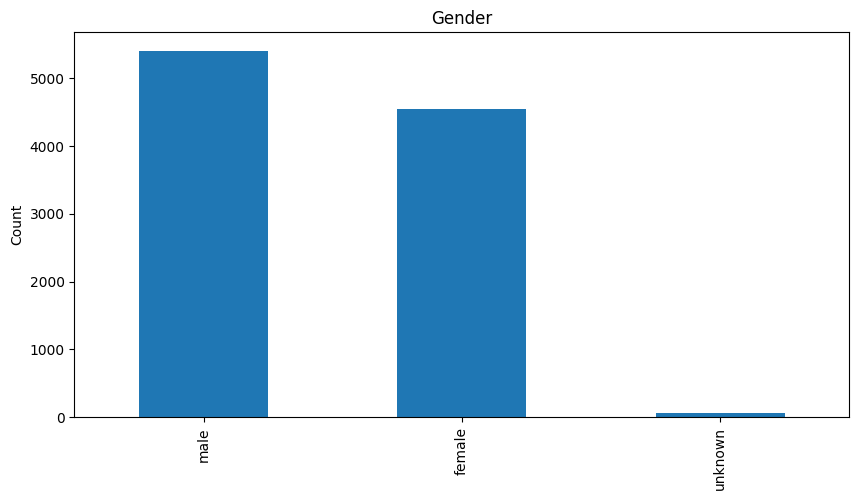

In [ ]:
# Plot the gender
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
df['sex'].value_counts().plot(kind='bar', ax=ax1)
plt.ylabel("Count")
plt.title('Gender')
plt.show()

From the plot above, skin diseases are more prominent in Men as compared to Women and other gender.

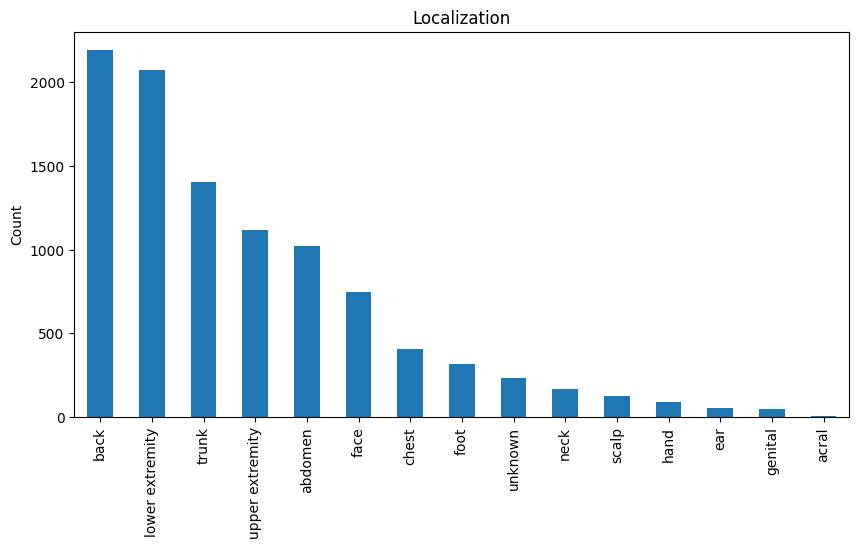

In [ ]:
# Plot the localization
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
df['localization'].value_counts().plot(kind='bar', ax=ax1)
plt.ylabel("Count")
plt.title('Localization')
plt.show()

From the plot above, skin diseases are more visible on the "back" of the body and least on the "acral surfaces"

## Bivariate Analysis
Let's plot the relationship between the lesion types and other features

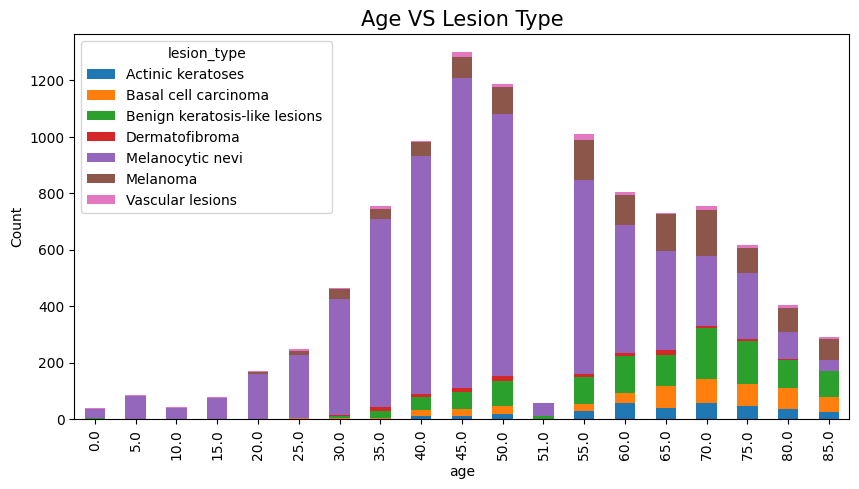

In [ ]:
# Plot the relationship between age and lesion type
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
# Use pandas crosstab to get the counts of age and lesion_type
counts = pd.crosstab(df['age'], df['lesion_type'])
# Plot the counts as a stacked bar plot on the axis
counts.plot(kind='bar', stacked=True, ax=ax1)
plt.ylabel("Count")
plt.title('Age VS Lesion Type', fontsize=15)
plt.show()

From the plot, most of the ages were affected "Melanocytic nevi". But it can noticed that as the age increases "Melanocytic nevi" reduces

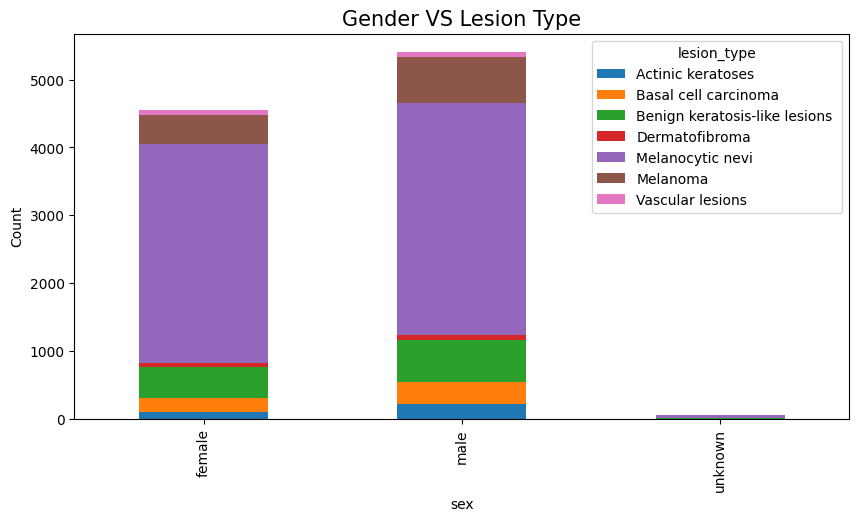

In [ ]:
# Plot the relationship between gender and lesion type
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
# Use pandas crosstab to get the counts of gender and lesion_type
counts = pd.crosstab(df['sex'], df['lesion_type'])
# Plot the counts as a stacked bar plot on the axis
counts.plot(kind='bar', stacked=True, ax=ax1)
plt.ylabel("Count")
plt.title('Gender VS Lesion Type', fontsize=15)
plt.show()

From the plot, there is little to no difference amongst the genders as they are mostly afected by "Melanocytic nevi"

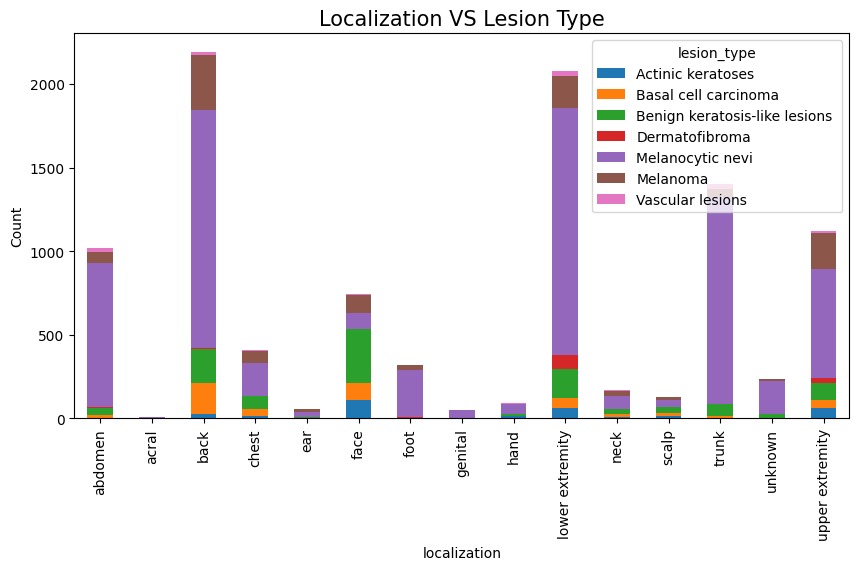

In [ ]:
# Plot the relationship between localization and lesion type
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
# Use pandas crosstab to get the counts of age and lesion_type
counts = pd.crosstab(df['localization'], df['lesion_type'])
# Plot the counts as a stacked bar plot on the axis
counts.plot(kind='bar', stacked=True, ax=ax1)
plt.ylabel("Count")
plt.title('Localization VS Lesion Type', fontsize=15)
plt.show()

From the plot above, most of the localization are mostly affected by "Melanocytic nevi" except the "face" which mostly affected by "Benign keratosis-like lesions"

# Data Preprocessing


In [ ]:
%%time
# Load the images into the dataframe df using the path and resize the images to improve the model's performance
df['image'] = df['image_path'].map(lambda x: np.asarray(Image.open(x).resize((100,75))))

CPU times: user 1min 30s, sys: 3.96 s, total: 1min 34s
Wall time: 30min 37s


In [ ]:
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_type,lesion_type_idx,image
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2,"[[[190, 153, 194], [192, 154, 196], [191, 153,..."
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2,"[[[23, 13, 22], [24, 14, 24], [25, 14, 28], [3..."
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2,"[[[185, 127, 137], [189, 133, 147], [194, 136,..."
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2,"[[[24, 11, 17], [26, 13, 22], [38, 21, 32], [5..."
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,2,"[[[134, 90, 113], [147, 102, 125], [159, 115, ..."


In [ ]:
# # Import the necessary module
# from google.colab import files

# # Save the dataframe as a pickle file
# df.to_pickle('/content/drive/MyDrive/Project/df_with_images.pkl')

# # # Download the file to your local drive
# # files.download('/content/drive/MyDrive/Project/df_with_images.pkl')


In [ ]:
# Load the dataframe with the images from the file
import pickle
with open('/content/drive/MyDrive/XAI/df_with_images.pkl', 'rb') as f:
    df = pickle.load(f)

In [ ]:
# Print sample images for each lesion type
n_samples = 7
plt.figure(figsize=(4*n_samples, 3*7)) # creates a figure
for i, (type_name, type_rows) in enumerate(df.sort_values(['lesion_type']).groupby('lesion_type')):
    for j, (_, c_row) in enumerate(type_rows.sample(n_samples, random_state=2018).iterrows()):
        ax = plt.subplot(7, n_samples, i*n_samples + j + 1) # creates an axis for each image
        ax.set_title(type_name)
        ax.imshow(c_row['image'])
        ax.axis('off')
plt.savefig('category_samples.png', dpi=300)

In [ ]:
# Print the the dimension of the images
df['image'].map(lambda x: x.shape).value_counts()

(75, 100, 3)    10015
Name: image, dtype: int64

In [ ]:
# Define the features data and the target data
features=df.drop(columns=['lesion_type_idx'],axis=1)
target=df['lesion_type_idx']

In [ ]:
# Split the data into train and test data
x_train1, x_test1, y_train1, y_test1 = train_test_split(features, target, test_size=0.25,random_state=2)

The feature data needs to be normalised aas it help improve the performance and generalisation of the machine learning model, by making the input images more consistent and comparable

In [ ]:
features.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,lesion_type,image
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,"[[[190, 153, 194], [192, 154, 196], [191, 153,..."
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,"[[[23, 13, 22], [24, 14, 24], [25, 14, 28], [3..."
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,"[[[185, 127, 137], [189, 133, 147], [194, 136,..."
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,"[[[24, 11, 17], [26, 13, 22], [38, 21, 32], [5..."
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/drive/MyDrive/Project/archive/HAM1000...,Benign keratosis-like lesions,"[[[134, 90, 113], [147, 102, 125], [159, 115, ..."


In [ ]:
features['lesion_type'].value_counts()

Melanocytic nevi                  6705
Melanoma                          1113
Benign keratosis-like lesions     1099
Basal cell carcinoma               514
Actinic keratoses                  327
Vascular lesions                   142
Dermatofibroma                     115
Name: lesion_type, dtype: int64

In [ ]:
target.value_counts()

4    6705
5    1113
2    1099
1     514
0     327
6     142
3     115
Name: lesion_type_idx, dtype: int64

In [ ]:
from sklearn.preprocessing import StandardScaler
# Normalise the features data
import numpy as np
from sklearn.preprocessing import StandardScaler

# Convert the image column of the dataframes to numpy arrays
x_train = np.asarray(x_train1['image'].tolist())/255
x_test = np.asarray(x_test1['image'].tolist())/255

# Reshape the data to two dimensions
x_train = np.reshape(x_train, (x_train.shape[0], -1))
x_test = np.reshape(x_test, (x_test.shape[0], -1))

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
x_train = scaler.fit_transform(x_train)

# Transform the testing data using the same scaler
x_test = scaler.transform(x_test)


The target data need to be encoded. One-hot encoding can help improve the performance and generalisation of the classification model, by making the labels more consistent and comparable.

In [ ]:
# Perform one-hot encoding on the training labels, using the number of classes as the argument
y_train = to_categorical(y_train1, num_classes = 7)
# Perform one-hot encoding on the testing labels, using the number of classes as the argument
y_test = to_categorical(y_test1, num_classes = 7)

In [ ]:
# To improve model performance, create a validation data
x_train, x_validate, y_train, y_validate = train_test_split(x_train, y_train, test_size = 0.1, random_state = 2)

# Get the number of samples in the training set
n_train = x_train.shape[0]

# Reshape the training set to a new shape of (n_train, 75, 100, 3)
# The first dimension is the number of samples
# The second dimension is the height of each image
# The third dimension is the width of each image
# The fourth dimension is the number of channels (RGB)
x_train = x_train.reshape(n_train, *(75, 100, 3))

# Repeat the same process for the testing and validation sets
n_test = x_test.shape[0]
x_test = x_test.reshape(n_test, *(75, 100, 3))
n_validate = x_validate.shape[0]
x_validate = x_validate.reshape(n_validate, *(75, 100, 3))

## Data Augmentation
The size of the current dataset can be increased. The concept is to apply slight modifications to the training set in order to replicate the variances.

Data augmentation strategies are methods that modify the training data in a way that modifies the array representation while maintaining the label. Grayscales, vertical and horizontal flips, random cropping, colour hiccups, translations, rotations, and much more are common augmentations used by users.

We can easily double or quadruple the number of training examples and build a very robust model by applying only a few of these adjustments to our training data.

In [ ]:
datagen = ImageDataGenerator(
        rotation_range=10,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.1, # Randomly zoom image
        width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.1)  # randomly shift images vertically (fraction of total height)

datagen.fit(x_train)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
y_id = np.array(df['lesion_type_idx'])

# compute weights for the loss function, because the problem is unbalanced
class_weights = np.around(compute_class_weight(class_weight='balanced',classes=np.unique(y_id),y=target),2)
class_weights = dict(zip(np.unique(y_id),class_weights))

print('The classes are unbalanced. We need to provide class_weights ')
print(class_weights)

The classes are unbalanced. We need to provide class_weights 
{0: 4.38, 1: 2.78, 2: 1.3, 3: 12.44, 4: 0.21, 5: 1.29, 6: 10.08}


In [ ]:
# Define a function to plot the confusion matrix
def plot_cm(cm, labels, title, normalize=False, cmap=plt.cm.Reds):
    """
    This function plots and shows the confusion matrix.
    Normalization can be enabled by setting `normalize=True`.
    """
    # Plot the matrix as an image with the given colormap
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    # Get the tick marks for the labels
    tick_marks = np.arange(len(labels))
    plt.xticks(tick_marks, labels, rotation=45)
    plt.yticks(tick_marks, labels)

    # Normalize the matrix if required
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Get the threshold for the text color
    thresh = cm.max() / 2.
    # Loop through the matrix and add the text
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    # Adjust the layout and add the labels
    plt.tight_layout()
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')

In [ ]:
# Create a function for Classification Report of the model
def classificationReport(model):

  # Building a Classification report
  Y_pred= model.predict(x_test)

  # Convert the predicted classes to one hot vectors
  Y_pred_classes = np.argmax(Y_pred, axis=1)

  # Convert the actual classes to one hot vectors
  Y_true = np.argmax(y_test, axis=1)

  ClR = classification_report(Y_true,Y_pred_classes)
  return ClR

# Create a function to display the Confusion Matrix of the model
def Disp_ConfutionMatrix(model,title= 'Confusion matrix of test data'):

  # Make the predictions from the test dataset
  Y_pred = model.predict(x_test)
  # Convert the predicted classes to one hot vectors
  Y_pred_classes = np.argmax(Y_pred, axis=1)
  # Convert the actual classes to one hot vectors
  Y_true = np.argmax(y_test, axis=1)
  # Calculate the confusion matrix
  confusion_mtx = confusion_matrix(Y_true, Y_pred_classes)

  # Plot the confusion matrix
  plot_cm(confusion_mtx, labels=range(7),title= title)

# CNN

In [ ]:
# Building Neural Network

# Define the input shape and the number of classes
input_shape = (75, 100, 3)
num_classes = 7

model = Sequential([

    # 1st convolutional layer
    Conv2D(filters=96, kernel_size=(11,11), strides=(4,4), activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPool2D(pool_size=(3,3), strides=(2,2)),

    # 2nd convolutional layer
    Conv2D(filters=256, kernel_size=(5,5), strides=(1,1), activation='relu', padding="same"),
    BatchNormalization(),
    MaxPool2D(pool_size=(3,3), strides=(2,2)),

    # 3rd convolutional layer
    Conv2D(filters=384, kernel_size=(3,3), strides=(1,1), activation='relu', padding="same"),
    BatchNormalization(),

    # 4th convolutional layer
    Conv2D(filters=384, kernel_size=(1,1), strides=(1,1), activation='relu', padding="same"),
    BatchNormalization(),

    # 5th convolutional layer
    Conv2D(filters=256, kernel_size=(1,1), strides=(1,1), activation='relu', padding="same"),
    BatchNormalization(),
    MaxPool2D(pool_size=(3,3), strides=(2,2)),

    Flatten(),

    # 6th, Dense layer
    Dense(4096, activation='relu'),
    Dropout(0.5),

    # 7th Dense layer
    Dense(4096, activation='relu'),
    Dropout(0.5),

    # 8th output layer
    Dense(num_classes, activation='softmax')
])
# Print the model summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 17, 23, 96)        34944     
                                                                 
 batch_normalization (Batch  (None, 17, 23, 96)        384       
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 8, 11, 96)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 8, 11, 256)        614656    
                                                                 
 batch_normalization_1 (Bat  (None, 8, 11, 256)        1024      
 chNormalization)                                                
                                                        

In [ ]:
%%time
# training
early_stopping_monitor = EarlyStopping(patience=100,monitor='val_accuracy')
model_checkpoint_callback = ModelCheckpoint(filepath='model.h5',
                                            save_weights_only=False,
                                            monitor='val_accuracy',
                                            mode='auto',
                                            save_best_only=True,
                                            verbose=1,min_lr=0.00001)
batch_size = 16
epochs = 100
optimizer = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-3)
model.compile(optimizer = optimizer, loss = 'categorical_crossentropy', metrics=['accuracy'])

history=model.fit(datagen.flow(x_train,y_train), epochs=epochs, batch_size=batch_size, shuffle=True, callbacks=[early_stopping_monitor,model_checkpoint_callback], validation_data=(x_test, y_test), class_weight=class_weights)

Epoch 1/100
212/212 [==============================] - ETA: 0s - loss: 2.0606 - accuracy: 0.3447
Epoch 1: val_accuracy improved from -inf to 0.38818, saving model to model.h5


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


212/212 [==============================] - 30s 102ms/step - loss: 2.0606 - accuracy: 0.3447 - val_loss: 1.6933 - val_accuracy: 0.3882
Epoch 2/100
212/212 [==============================] - ETA: 0s - loss: 1.7631 - accuracy: 0.4119
Epoch 2: val_accuracy improved from 0.38818 to 0.48442, saving model to model.h5
212/212 [==============================] - 20s 92ms/step - loss: 1.7631 - accuracy: 0.4119 - val_loss: 1.3029 - val_accuracy: 0.4844
Epoch 3/100
212/212 [==============================] - ETA: 0s - loss: 1.5394 - accuracy: 0.4483
Epoch 3: val_accuracy improved from 0.48442 to 0.50479, saving model to model.h5
212/212 [==============================] - 16s 78ms/step - loss: 1.5394 - accuracy: 0.4483 - val_loss: 1.2626 - val_accuracy: 0.5048
Epoch 4/100
212/212 [==============================] - ETA: 0s - loss: 1.4039 - accuracy: 0.4764
Epoch 4: val_accuracy improved from 0.50479 to 0.52756, saving model to model.h5
212/212 [==============================] - 20s 95ms/step - loss: 1

## Model Evaluation

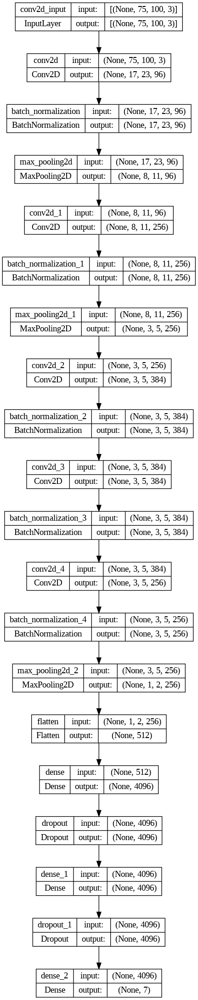

In [ ]:
# Plot the model function

# Plot the model to a file
plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

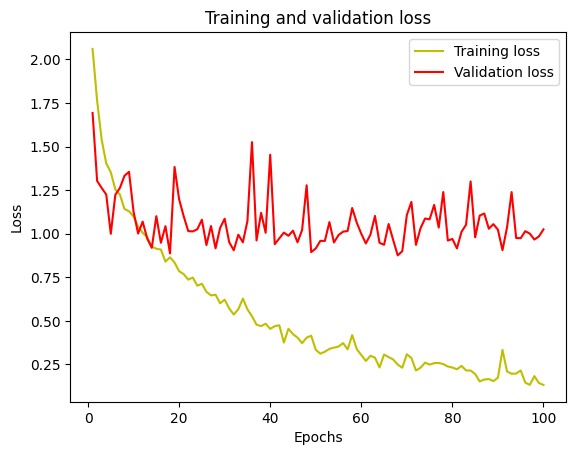

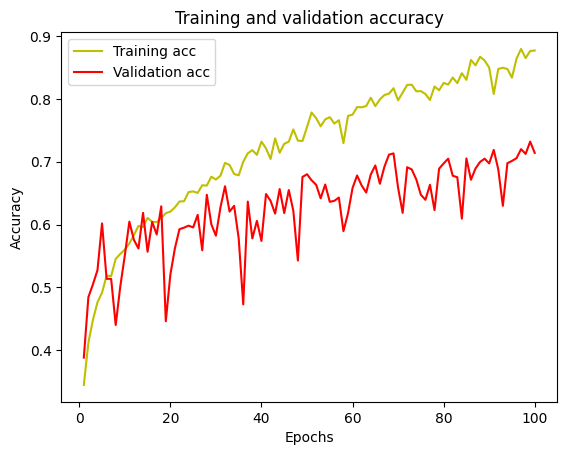

In [ ]:
#plot the training and validation accuracy and loss at each epoch
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
# # Save the model to a file
# model.save('my_model.keras')

# Load the model from the file
model = keras.models.load_model('/content/drive/MyDrive/XAI/model.h5')

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f" % (accuracy_v))
print("Test: accuracy = %f" % (accuracy))

pred = model.predict(x_test)

24/24 [==============================] - 0s 13ms/step - loss: 0.9944 - accuracy: 0.7327
Validation: accuracy = 0.732713
Test: accuracy = 0.732029
79/79 [==============================] - 0s 4ms/step


In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f" % (accuracy_v))
print("Test: accuracy = %f" % (accuracy))

pred = model.predict(x_test)

24/24 [==============================] - 0s 13ms/step - loss: 0.9944 - accuracy: 0.7327
Validation: accuracy = 0.732713
Test: accuracy = 0.732029
79/79 [==============================] - 0s 4ms/step


79/79 [==============================] - 1s 7ms/step


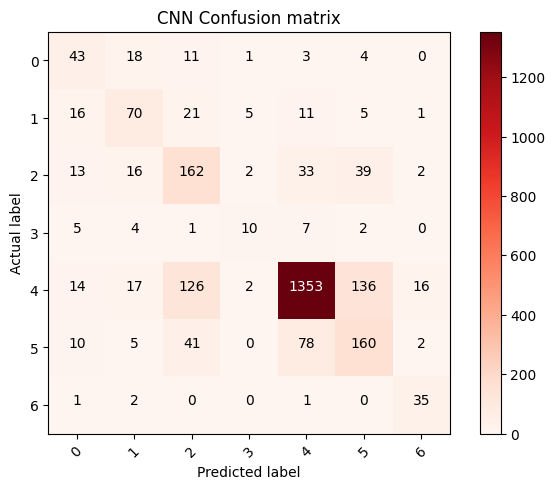

In [ ]:
# Plot the confusion matrix
Disp_ConfutionMatrix(model, title='CNN Confusion matrix')

In [ ]:
# Classification Report for CNN
print(classificationReport(model))

79/79 [==============================] - 1s 6ms/step
              precision    recall  f1-score   support

           0       0.42      0.54      0.47        80
           1       0.53      0.54      0.54       129
           2       0.45      0.61      0.52       267
           3       0.50      0.34      0.41        29
           4       0.91      0.81      0.86      1664
           5       0.46      0.54      0.50       296
           6       0.62      0.90      0.74        39

    accuracy                           0.73      2504
   macro avg       0.56      0.61      0.58      2504
weighted avg       0.76      0.73      0.74      2504



# VGG16

In [ ]:
# Define the input shape and the number of classes
input_shape = (75, 100, 3)
num_classes = 7

In [ ]:
# Load the pre-trained VGG16 model without the top (fully connected) layers
base_model = VGG16(input_shape=input_shape, pooling='avg', weights='imagenet', include_top=False)

# Add your own classifier on top
x = Dropout(0.2)(base_model.output)
x = Dense(128, activation="relu")(x)
predictions = Dense(num_classes, activation="softmax")(x)

# Create the final model
VGG16model = Model(inputs=base_model.input, outputs=predictions)


# Print the model summary
VGG16model.summary()

58889256/58889256 [==============================] - 1s 0us/step
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 75, 100, 3)]      0         
                                                                 
 block1_conv1 (Conv2D)       (None, 75, 100, 64)       1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 75, 100, 64)       36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 37, 50, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 37, 50, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 37, 50, 128)       147584    
                                                              

In [ ]:
early_stopping_monitor = EarlyStopping(patience=100,monitor='val_accuracy')
model_checkpoint_callback = ModelCheckpoint(filepath='/content/drive/MyDrive/XAI/Models/VGG16model.h5',
                                            save_weights_only=False,
                                            monitor='val_accuracy',
                                            mode='auto',
                                            save_best_only=True,
                                            verbose=1,min_lr=0.00001)
batch_size = 20
epochs = 100
optimizer = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-3)
VGG16model.compile(optimizer = optimizer , loss = "categorical_crossentropy", metrics=["accuracy"])

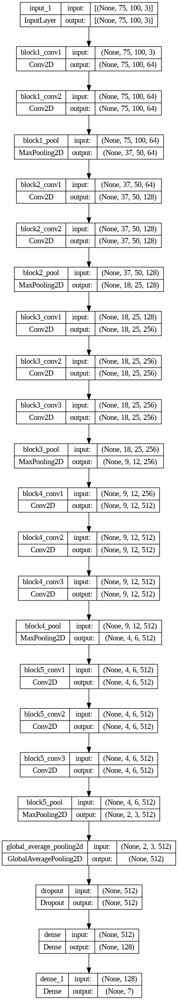

In [ ]:
# Plot the VGG16model to a file
plot_model(VGG16model, to_file='/content/drive/MyDrive/XAI/VGG16model_plot.png', show_shapes=True, show_layer_names=True)

In [ ]:
%%time
VGG16_history=VGG16model.fit(datagen.flow(x_train,y_train), epochs=epochs, batch_size=batch_size, shuffle=True, callbacks=[early_stopping_monitor,model_checkpoint_callback], validation_data=(x_validate, y_validate), class_weight=class_weights)

Epoch 1/100
212/212 [==============================] - ETA: 0s - loss: 1.6219 - accuracy: 0.3949
Epoch 1: val_accuracy improved from -inf to 0.47872, saving model to /content/drive/MyDrive/XAI/Models/VGG16model.h5


You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.


212/212 [==============================] - 48s 168ms/step - loss: 1.6219 - accuracy: 0.3949 - val_loss: 1.4799 - val_accuracy: 0.4787
Epoch 2/100
212/212 [==============================] - ETA: 0s - loss: 1.2363 - accuracy: 0.5511
Epoch 2: val_accuracy improved from 0.47872 to 0.51064, saving model to /content/drive/MyDrive/XAI/Models/VGG16model.h5
212/212 [==============================] - 24s 113ms/step - loss: 1.2363 - accuracy: 0.5511 - val_loss: 1.2191 - val_accuracy: 0.5106
Epoch 3/100
212/212 [==============================] - ETA: 0s - loss: 1.0717 - accuracy: 0.5930
Epoch 3: val_accuracy improved from 0.51064 to 0.55984, saving model to /content/drive/MyDrive/XAI/Models/VGG16model.h5
212/212 [==============================] - 24s 115ms/step - loss: 1.0717 - accuracy: 0.5930 - val_loss: 1.0778 - val_accuracy: 0.5598
Epoch 4/100
212/212 [==============================] - ETA: 0s - loss: 0.9672 - accuracy: 0.6115
Epoch 4: val_accuracy improved from 0.55984 to 0.59840, saving mode

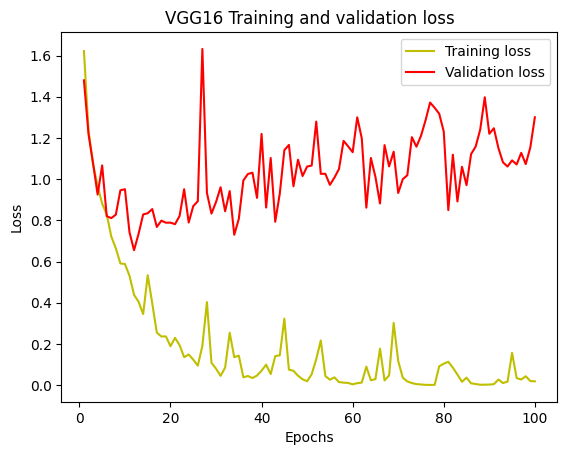

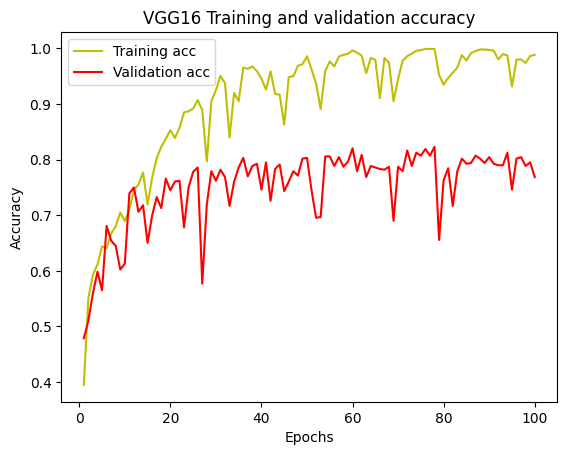

In [ ]:
#plot the training and validation accuracy and loss at each epoch
loss = VGG16_history.history['loss']
val_loss = VGG16_history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('VGG16 Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = VGG16_history.history['accuracy']
val_acc = VGG16_history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('VGG16 Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Load the VGG16model from the file
VGG16model = keras.models.load_model('/content/drive/MyDrive/XAI/Models/VGG16model.h5')

In [ ]:
loss, accuracy = VGG16model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = VGG16model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f" % (accuracy_v))
print("Test: accuracy = %f" % (accuracy))

pred = VGG16model.predict(x_test)

24/24 [==============================] - 1s 24ms/step - loss: 1.3465 - accuracy: 0.8231
Validation: accuracy = 0.823138
Test: accuracy = 0.830272
79/79 [==============================] - 2s 24ms/step


79/79 [==============================] - 2s 23ms/step


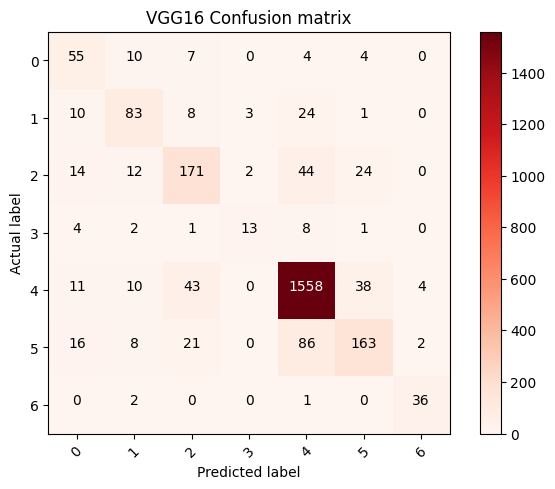

In [ ]:
# Plot the confusion matrix
Disp_ConfutionMatrix(VGG16model,title='VGG16 Confusion matrix')

In [ ]:
# Classification Report for VGG16model
print(classificationReport(VGG16model))

79/79 [==============================] - 2s 24ms/step
              precision    recall  f1-score   support

           0       0.50      0.69      0.58        80
           1       0.65      0.64      0.65       129
           2       0.68      0.64      0.66       267
           3       0.72      0.45      0.55        29
           4       0.90      0.94      0.92      1664
           5       0.71      0.55      0.62       296
           6       0.86      0.92      0.89        39

    accuracy                           0.83      2504
   macro avg       0.72      0.69      0.70      2504
weighted avg       0.83      0.83      0.83      2504



# ResNet50

In [ ]:
# Load the pre-trained ResNet50 model without the top (fully connected) layers
base_model = ResNet50(input_shape=input_shape, pooling='avg', weights='imagenet', include_top=False)

# Add your own classifier on top
x = Dropout(0.2)(base_model.output)
x = Dense(128, activation="relu")(x)
predictions = Dense(num_classes, activation="softmax")(x)

# Create the final model
ResNet50model = Model(inputs=base_model.input, outputs=predictions)


# Print the model summary
ResNet50model.summary()

94765736/94765736 [==============================] - 1s 0us/step
Model: "model_60"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 75, 100, 3)]         0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 81, 106, 3)           0         ['input_2[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 38, 50, 64)           9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 38, 50, 64)           256       ['conv1_conv[0][0]']          
 on)                      

In [ ]:
early_stopping_monitor = EarlyStopping(patience=100,monitor='val_accuracy')
model_checkpoint_callback = ModelCheckpoint(filepath='/content/drive/MyDrive/XAI/Models/ResNet50model.h5',
                                            save_weights_only=False,
                                            monitor='val_accuracy',
                                            mode='auto',
                                            save_best_only=True,
                                            verbose=1,min_lr=0.00001)
batch_size = 20
epochs = 100
optimizer = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-3)
ResNet50model.compile(optimizer = optimizer , loss = "categorical_crossentropy", metrics=["accuracy"])

In [ ]:
# Plot the VGG16model to a file
plot_model(ResNet50model, to_file='/content/drive/MyDrive/XAI/ResNet50model_plot.png', show_shapes=True, show_layer_names=True)

In [ ]:
%%time
ResNet50model_history=ResNet50model.fit(datagen.flow(x_train,y_train), epochs=epochs, batch_size=batch_size, shuffle=True, callbacks=[early_stopping_monitor,model_checkpoint_callback], validation_data=(x_validate, y_validate), class_weight=class_weights)

Epoch 1/100
212/212 [==============================] - ETA: 0s - loss: 1.5151 - accuracy: 0.4382
Epoch 1: val_accuracy improved from -inf to 0.63298, saving model to /content/drive/MyDrive/XAI/Models/ResNet50model.h5


You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.


212/212 [==============================] - 71s 163ms/step - loss: 1.5151 - accuracy: 0.4382 - val_loss: 1.3615 - val_accuracy: 0.6330
Epoch 2/100
212/212 [==============================] - ETA: 0s - loss: 0.9371 - accuracy: 0.6165
Epoch 2: val_accuracy improved from 0.63298 to 0.64229, saving model to /content/drive/MyDrive/XAI/Models/ResNet50model.h5
212/212 [==============================] - 40s 187ms/step - loss: 0.9371 - accuracy: 0.6165 - val_loss: 1.8036 - val_accuracy: 0.6423
Epoch 3/100
212/212 [==============================] - ETA: 0s - loss: 0.7103 - accuracy: 0.6742
Epoch 3: val_accuracy did not improve from 0.64229
212/212 [==============================] - 31s 148ms/step - loss: 0.7103 - accuracy: 0.6742 - val_loss: 1.1559 - val_accuracy: 0.6077
Epoch 4/100
212/212 [==============================] - ETA: 0s - loss: 0.6236 - accuracy: 0.7108
Epoch 4: val_accuracy improved from 0.64229 to 0.74468, saving model to /content/drive/MyDrive/XAI/Models/ResNet50model.h5
212/212 [=

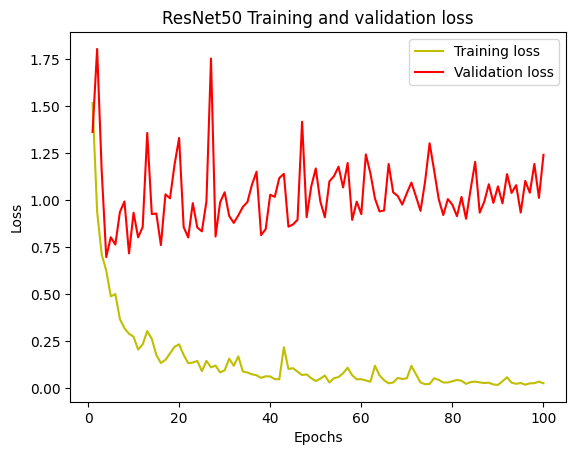

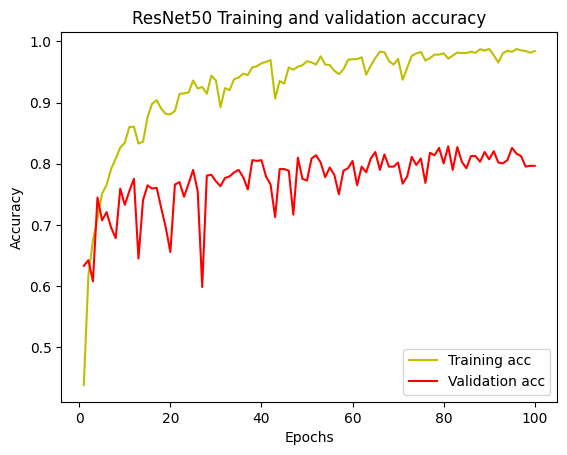

In [ ]:
#plot the training and validation accuracy and loss at each epoch
loss = ResNet50model_history.history['loss']
val_loss = ResNet50model_history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('ResNet50 Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = ResNet50model_history.history['accuracy']
val_acc = ResNet50model_history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('ResNet50 Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
# Load the ResNet50model from the file
ResNet50model = keras.models.load_model('/content/drive/MyDrive/XAI/Models/ResNet50model.h5')

In [ ]:
loss, accuracy = ResNet50model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = ResNet50model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f" % (accuracy_v))
print("Test: accuracy = %f" % (accuracy))

pred = ResNet50model.predict(x_test)

24/24 [==============================] - 1s 58ms/step - loss: 0.9133 - accuracy: 0.8285
Validation: accuracy = 0.828457
Test: accuracy = 0.822284
79/79 [==============================] - 3s 23ms/step


79/79 [==============================] - 2s 20ms/step


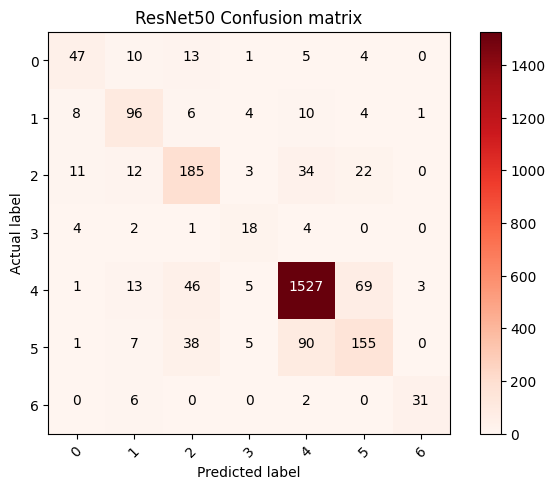

In [ ]:
# Plot the confusion matrix
Disp_ConfutionMatrix(ResNet50model,title='ResNet50 Confusion matrix')

In [ ]:
# Classification Report for ResNet50model
print(classificationReport(ResNet50model))

79/79 [==============================] - 2s 21ms/step
              precision    recall  f1-score   support

           0       0.65      0.59      0.62        80
           1       0.66      0.74      0.70       129
           2       0.64      0.69      0.67       267
           3       0.50      0.62      0.55        29
           4       0.91      0.92      0.92      1664
           5       0.61      0.52      0.56       296
           6       0.89      0.79      0.84        39

    accuracy                           0.82      2504
   macro avg       0.69      0.70      0.69      2504
weighted avg       0.82      0.82      0.82      2504



# MobileNet

In [ ]:
# Load the pre-trained MobileNet model without the top (fully connected) layers
base_model = MobileNet(input_shape=input_shape, pooling='avg', weights='imagenet', include_top=False)

# Add your own classifier on top
x = Dropout(0.2)(base_model.output)
x = Dense(128, activation="relu")(x)
predictions = Dense(num_classes, activation="softmax")(x)

# Create the final model
MobileNetmodel = Model(inputs=base_model.input, outputs=predictions)


# Print the model summary
MobileNetmodel.summary()

17225924/17225924 [==============================] - 0s 0us/step
Model: "model_61"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 75, 100, 3)]      0         
                                                                 
 conv1 (Conv2D)              (None, 38, 50, 32)        864       
                                                                 
 conv1_bn (BatchNormalizati  (None, 38, 50, 32)        128       
 on)                                                             
                                                                 
 conv1_relu (ReLU)           (None, 38, 50, 32)        0         
                                                                 
 conv_dw_1 (DepthwiseConv2D  (None, 38, 50, 32)        288       
 )                                                               
                                                           

In [ ]:
early_stopping_monitor = EarlyStopping(patience=100,monitor='val_accuracy')
model_checkpoint_callback = ModelCheckpoint(filepath='/content/drive/MyDrive/XAI/Models/MobileNetmodel.h5',
                                            save_weights_only=False,
                                            monitor='val_accuracy',
                                            mode='auto',
                                            save_best_only=True,
                                            verbose=1,min_lr=0.00001)
batch_size = 20
epochs = 100
optimizer = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-3)
MobileNetmodel.compile(optimizer = optimizer , loss = "categorical_crossentropy", metrics=["accuracy"])

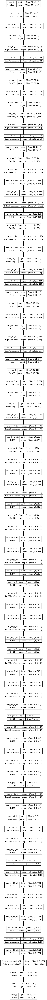

In [ ]:
# Plot the MobileNetmodel to a file
plot_model(MobileNetmodel, to_file='/content/drive/MyDrive/XAI/MobileNetmodel_plot.png', show_shapes=True, show_layer_names=True)

In [ ]:
%%time
MobileNetmodel_history=MobileNetmodel.fit(datagen.flow(x_train,y_train), epochs=epochs, batch_size=batch_size, shuffle=True, callbacks=[early_stopping_monitor,model_checkpoint_callback], validation_data=(x_validate, y_validate), class_weight=class_weights)

Epoch 1/100
212/212 [==============================] - ETA: 0s - loss: 2.0843 - accuracy: 0.3037
Epoch 1: val_accuracy improved from -inf to 0.56250, saving model to /content/drive/MyDrive/XAI/Models/MobileNetmodel.h5


You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.


212/212 [==============================] - 35s 99ms/step - loss: 2.0843 - accuracy: 0.3037 - val_loss: 1.2712 - val_accuracy: 0.5625
Epoch 2/100
212/212 [==============================] - ETA: 0s - loss: 1.4007 - accuracy: 0.4826
Epoch 2: val_accuracy improved from 0.56250 to 0.60372, saving model to /content/drive/MyDrive/XAI/Models/MobileNetmodel.h5
212/212 [==============================] - 19s 92ms/step - loss: 1.4007 - accuracy: 0.4826 - val_loss: 1.1199 - val_accuracy: 0.6037
Epoch 3/100
212/212 [==============================] - ETA: 0s - loss: 1.1363 - accuracy: 0.5561
Epoch 3: val_accuracy improved from 0.60372 to 0.65824, saving model to /content/drive/MyDrive/XAI/Models/MobileNetmodel.h5
212/212 [==============================] - 20s 96ms/step - loss: 1.1363 - accuracy: 0.5561 - val_loss: 0.9722 - val_accuracy: 0.6582
Epoch 4/100
212/212 [==============================] - ETA: 0s - loss: 0.9541 - accuracy: 0.5897
Epoch 4: val_accuracy did not improve from 0.65824
212/212 [==

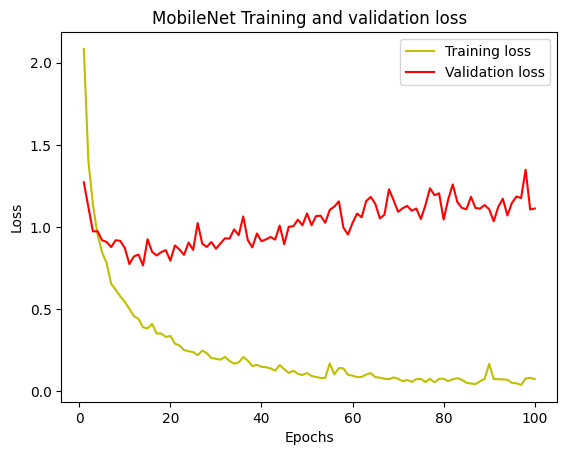

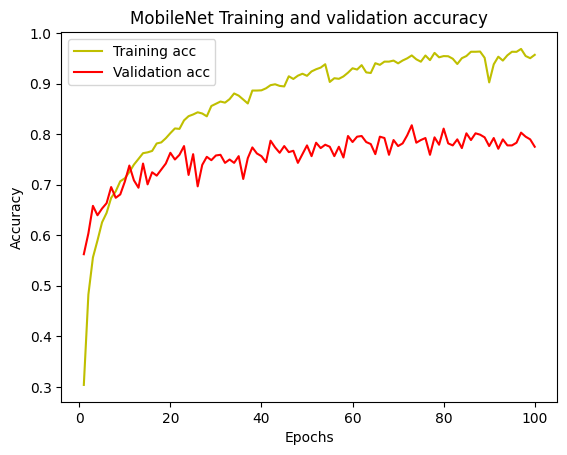

In [ ]:
#plot the training and validation accuracy and loss at each epoch
loss = MobileNetmodel_history.history['loss']
val_loss = MobileNetmodel_history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('MobileNet Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = MobileNetmodel_history.history['accuracy']
val_acc = MobileNetmodel_history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('MobileNet Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
loss, accuracy = MobileNetmodel.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = MobileNetmodel.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f" % (accuracy_v))
print("Test: accuracy = %f" % (accuracy))

pred = MobileNetmodel.predict(x_test)

24/24 [==============================] - 0s 9ms/step - loss: 1.0983 - accuracy: 0.8178
Validation: accuracy = 0.817819
Test: accuracy = 0.819489
79/79 [==============================] - 1s 8ms/step


In [ ]:
# Load the MobileNetmodel from the file
MobileNetmodel = keras.models.load_model('/content/drive/MyDrive/XAI/Models/MobileNetmodel.h5')

79/79 [==============================] - 1s 8ms/step


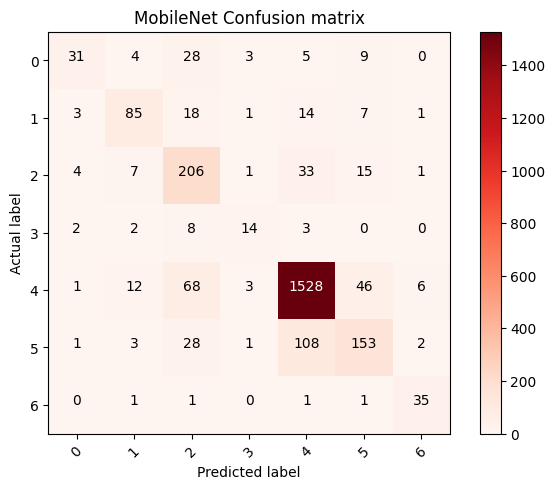

In [ ]:
# Plot the confusion matrix
Disp_ConfutionMatrix(MobileNetmodel,title='MobileNet Confusion matrix')

In [ ]:
# Classification Report for MobileNetmodel
print(classificationReport(MobileNetmodel))

79/79 [==============================] - 1s 7ms/step
              precision    recall  f1-score   support

           0       0.74      0.39      0.51        80
           1       0.75      0.66      0.70       129
           2       0.58      0.77      0.66       267
           3       0.61      0.48      0.54        29
           4       0.90      0.92      0.91      1664
           5       0.66      0.52      0.58       296
           6       0.78      0.90      0.83        39

    accuracy                           0.82      2504
   macro avg       0.72      0.66      0.68      2504
weighted avg       0.82      0.82      0.82      2504



# Model Evaluation

After the evaluation of the models applied, it can be conluded that the model with the highest accuracy is VGG16.

In [ ]:
# Let's check out images that were wrongly predicted

# Make the predictions from the test dataset
Y_pred = VGG16model.predict(x_test)
# Convert the predicted classes to one hot vectors
Y_pred_classes = np.argmax(Y_pred, axis=1)
# Convert the actual classes to one hot vectors
Y_true = np.argmax(y_test, axis=1)

# Check wrong predictions
errors = (Y_pred_classes - Y_true != 0)

Y_pred_classes_errors = Y_pred_classes[errors]
Y_pred_errors = Y_pred[errors]
Y_true_errors = Y_true[errors]
X_test_errors = scaler.inverse_transform(x_test[errors].reshape(-1, 3*75*100))

79/79 [==============================] - 7s 33ms/step


In [ ]:
# Create a function to display images that were falsely predicted
def display_errors(errors_index,img_errors,pred_errors, obs_errors):
    """ This function shows 10 images with their predicted and real labels"""
    n = 0
    nrows = 2
    ncols = 5
    fig, ax = plt.subplots(nrows,ncols,sharex=True,sharey=True,figsize=(20, 8))
    for row in range(nrows):
        for col in range(ncols):
            error = errors_index[n]
            ax[row,col].imshow((img_errors[error]).reshape(75,100,3))
            ax[row,col].set_title("Predicted label :{}\nTrue label :{}".format(pred_errors[error],obs_errors[error]))
            n += 1
    plt.show()

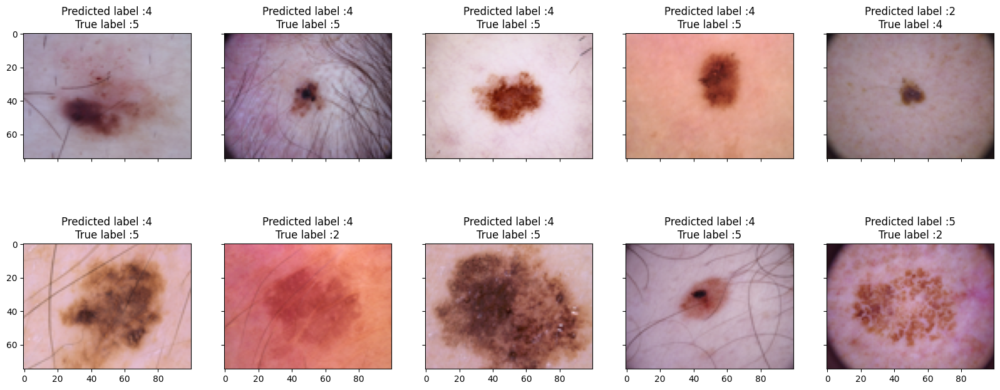

In [ ]:
# Calculate the highest probability prediction for each error instance
y_pred_errors_prob = np.max(Y_pred_errors, axis=1)

# Extract the probabilities of the true classes for each error instance
true_prob_errors = np.diagonal(np.take(Y_pred_errors, Y_true_errors, axis=1))

# Calculate the difference between the predicted probability and the true class probability
delta_pred_true_errors = y_pred_errors_prob - true_prob_errors

# Sort the instances by the delta of prediction and true probabilities
sorted_delta_errors = np.argsort(delta_pred_true_errors)

# Identify the 10 most significant errors
most_important_errors = sorted_delta_errors[-10:]

# Display the most significant errors
display_errors(most_important_errors, X_test_errors, Y_pred_classes_errors, Y_true_errors)


# XAI

Each XAI technique will applied on both the correctly classified data and the incorrectly clasified data


In [ ]:
# Let's seperate our test set into correctly predicted and incorrectly predicted

# Separate correctly classified data
correct_indices = np.where(Y_pred_classes == Y_true)[0]
correct_test_images = x_test[correct_indices]
correct_test_labels = y_test[correct_indices]

# Separate incorrectly classified data
incorrect_indices = np.where(Y_pred_classes != Y_true)[0]
incorrect_test_images = x_test[incorrect_indices]
incorrect_test_labels = y_test[incorrect_indices]


In [ ]:
# Create a function to untransform the images
def untransform_image(image):
  """
  This function takes an image and a scaler and returns the image in its untransformed format.

  Args:
      image: The image (numpy array) to be untransformed.
      scaler: The MinMaxScaler object used for normalization.

  Returns:
      The untransformed image (numpy array).
  """
  # Reshape the image to a flat array
  flat_image = image.reshape(-1, 3*75*100)

  # Apply inverse transform using the scaler
  untransformed_flat = scaler.inverse_transform(flat_image)

  # Reshape back to the original image format
  untransformed_image = untransformed_flat.reshape(-1, 75, 100, 3)

  return untransformed_image

In [ ]:
# Untransform the x_train and x_test images
x_train_untransformed = untransform_image(x_train)
x_test_untransformed = untransform_image(x_test)
print("Untransformed x_train shape ",x_train_untransformed.shape,"\n")
print("Untransformed x_test shape ",x_test_untransformed.shape)
# VGG16model

Untransformed x_train shape  (6759, 75, 100, 3) 

Untransformed x_test shape  (2504, 75, 100, 3)


Plot out how each class look like

In [ ]:
class_names = ['Actinic keratoses','Basal cell carcinoma','Benign keratosis', \
               'Dermatofibroma','Melanocytic nevi','Melanoma','Vascular lesions']

In [ ]:
class_names_dict = {0:'Actinic keratoses', 1:'Basal cell carcinoma', 2:'Benign keratosis',
               3:'Dermatofibroma', 4:'Melanocytic nevi', 5:'Melanoma', 6:'Vascular lesions'}

In [ ]:
# Save an example for each category in a dict
y_train1 = np.argmax(y_train, axis=1)
images_dict = dict()
for i, l in enumerate(y_train1):
  if len(images_dict)==7:
    break

  # if tuple(l) not in images_dict.keys():
  #     images_dict[tuple(l)] = x_train[i]

  if l not in images_dict.keys():
    images_dict[l] = untransform_image(x_train[i])

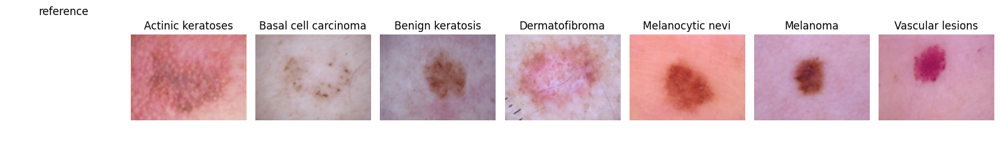

In [ ]:
# Function to plot images
def plot_categories(images):
  fig, axes = plt.subplots(1, 8, figsize=(16, 15))
  axes = axes.flatten()

  # Plot an empty canvas
  ax = axes[0]
  dummy_array = np.array([[[0, 0, 0, 0]]], dtype='uint8')
  ax.set_title("reference")
  ax.set_axis_off()
  ax.imshow(dummy_array, interpolation='nearest')

  # Plot an image for every category
  for k,v in images.items():
    ax = axes[k+1]
    ax.imshow(v[0], cmap=plt.cm.binary)
    ax.set_title(f"{class_names[k]}")
    ax.set_axis_off()

  plt.tight_layout()
  plt.show()


# Use the function to plot
plot_categories(images_dict)

In [ ]:
# So we can properly visualise these values for each class, create an array that contains one element of each class from the test set:
# Save an example of each class from the test set
def x_test_each_class(x_test, y_test):
  # Convert the actual classes to one hot vectors
  y_test = np.argmax(y_test, axis=1)
  x_test_dict = dict()
  for i, l in enumerate(y_test):
    if len(x_test_dict)==7:
      break
    if l not in x_test_dict.keys():
      x_test_dict[l] = x_test[i]

  # Convert to list preserving order of classes
  x_test_each_class = [x_test_dict[i] for i in sorted(x_test_dict)]

  # Convert to tensor
  x_test_each_class = np.asarray(x_test_each_class)
  return x_test_each_class

In [ ]:
x_test_each_class_correct = x_test_each_class(correct_test_images, correct_test_labels)
# Print shape of tensor
print(f"x_test_each_class tensor has shape: {x_test_each_class_correct.shape}")

x_test_each_class tensor has shape: (7, 75, 100, 3)


In [ ]:
# An example of image each class from the test set for incorrectly predicted data
x_test_each_class_incorrect = x_test_each_class(incorrect_test_images, incorrect_test_labels)
# Print shape of tensor
print(f"x_test_each_class tensor has shape: {x_test_each_class_incorrect.shape}")

x_test_each_class tensor has shape: (7, 75, 100, 3)


## SHAP
SHapley Additive exPlanations

In [ ]:
print(f"Shap version used: {shap.__version__}")

Shap version used: 0.44.0


### GradientExplainer

In [ ]:
# ... SHAP implementation ...
def explain_with_shap(image, model, background_data=None):
  """
  This function generates SHAP explanations for an image using the provided model and optionally background data.

  Args:
      image: The image (numpy array) to be explained.
      model: The model to use for generating predictions.
      background_data: The background data (optional) used by SHAP explainer.

  Returns:
      A list of SHAP values for each image instance.
  """
  if background_data is None:
    background_data = x_train[:]  # Use default background data if not provided
  explainer = shap.GradientExplainer(model, background_data)
  shap_values = explainer.shap_values(image)
  return shap_values

### Correctly predicted Shap Explanation

In [ ]:
# Before computing the shap values, make sure that the model is able to correctly classify each one of the examples you just picked:

# Compute predictions
predictions = VGG16model.predict(x_test_each_class_correct)

# Apply argmax to get predicted class
np.argmax(predictions, axis=1)


1/1 [==============================] - 0s 19ms/step


array([0, 1, 2, 3, 4, 5, 6])

In [ ]:
%%time

shap_values = explain_with_shap(x_test_each_class_correct, VGG16model)

`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


CPU times: user 23.8 s, sys: 112 ms, total: 23.9 s
Wall time: 24.4 s


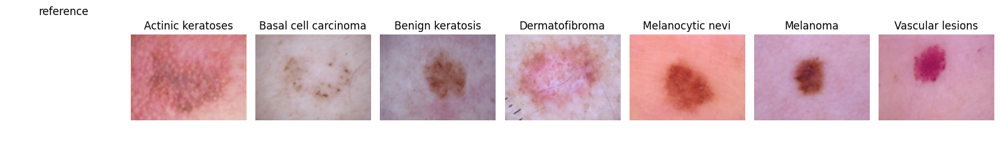

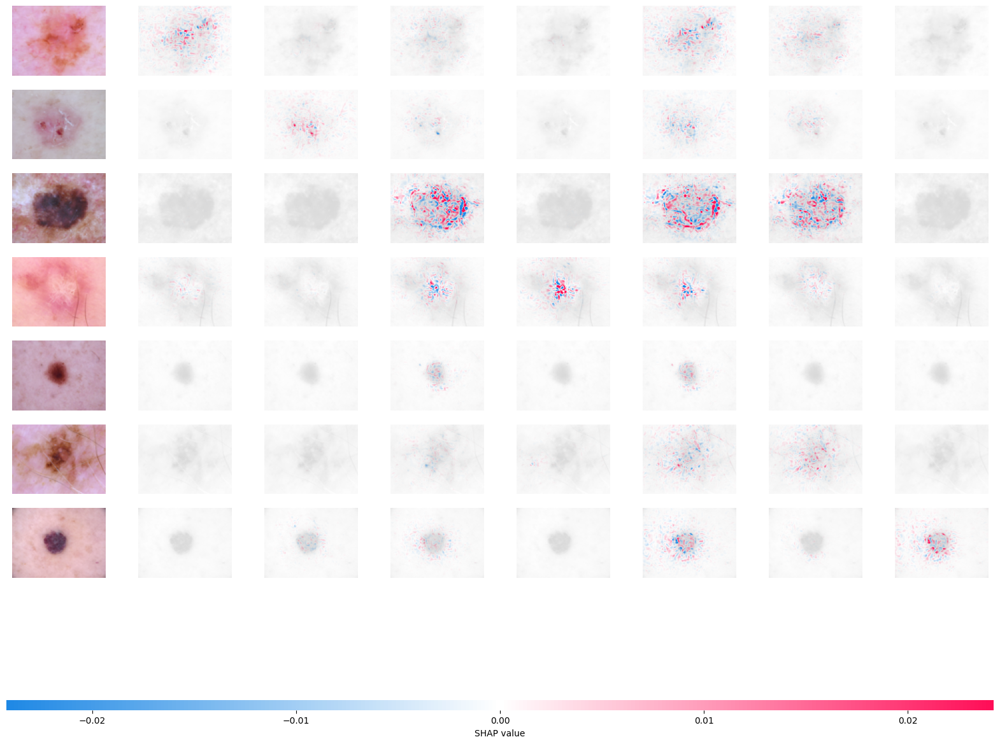

In [ ]:
# Plot reference column
plot_categories(images_dict)

# Print an empty line to separate the two plots
print()

# Plot shap values
shap.image_plot(shap_values, untransform_image(x_test_each_class_correct))

In [ ]:
# Check for stabilty
# To do that we are going to add noise to the images and see how this affects our SHAP explanations

#### Noise

In [ ]:
def add_noise(image, noise_type, noise_level):
  """
  Adds noise to an image.

  Args:
      image: The original image as a numpy array.
      noise_type: The type of noise to add (e.g., "gaussian", "salt_and_pepper", "shot").
      noise_level: The level of noise to add (e.g., standard deviation for gaussian noise).

  Returns:
      The noisy image as a numpy array.
  """

  if noise_type == "gaussian":
    noise = np.random.normal(scale=noise_level, size=image.shape)
    noisy_image = image + noise
  elif noise_type == "salt_and_pepper":
    noise_prob = noise_level
    salt_value = 255
    pepper_value = 0
    num_pixels = image.shape[0] * image.shape[1]
    num_salt = int(noise_prob * num_pixels)
    num_pepper = int(noise_prob * num_pixels)
    salt_pixels = np.random.randint(0, num_pixels, num_salt)
    pepper_pixels = np.random.randint(0, num_pixels, num_pepper)
    noisy_image = image.copy()
    noisy_image.flat[salt_pixels] = salt_value
    noisy_image.flat[pepper_pixels] = pepper_value
  elif noise_type == "shot":
    # Simulate shot noise using Poisson distribution (adjust parameters as needed)
    rows, cols = image.shape[:2]
    random_poisson = np.random.poisson(image + 1, size=(rows, cols))
    noisy_image = np.random.random(image.shape) * random_poisson
  else:
    raise ValueError("Unsupported noise type:", noise_type)

  # Clip noisy image to valid pixel range (0-255)
  noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
  return noisy_image


def add_noise_to_images(images, noise_type, noise_level):
  """
  Adds noise to a NumPy array of images.

  Args:
      images: A NumPy array of images with shape (num_images, height, width, channels).
      noise_type: The type of noise to add.
      noise_level: The level of noise to add.

  Returns:
      A NumPy array of noisy images with the same shape as the input.
  """
  noisy_images = np.empty_like(images)  # Create empty array with same shape
  for i in range(images.shape[0]):
    noisy_image = add_noise(images[i], noise_type, noise_level)
    noisy_images[i] = noisy_image
  return noisy_images


In [ ]:
# Add Gaussian noise with standard deviation 10
noisy_image_gaussian = add_noise(image.copy(), "gaussian", 10)

In [ ]:
noisy_images = add_noise_to_images(x_test_each_class_correct, "gaussian", 0.5)

# noisy_images will now be a NumPy array containing noisy versions of the original images

In [ ]:
%%time

shap_values = explain_with_shap(noisy_images, VGG16model)

`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


CPU times: user 20 s, sys: 140 ms, total: 20.2 s
Wall time: 20.7 s


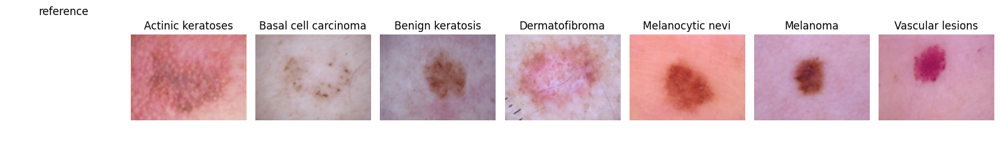

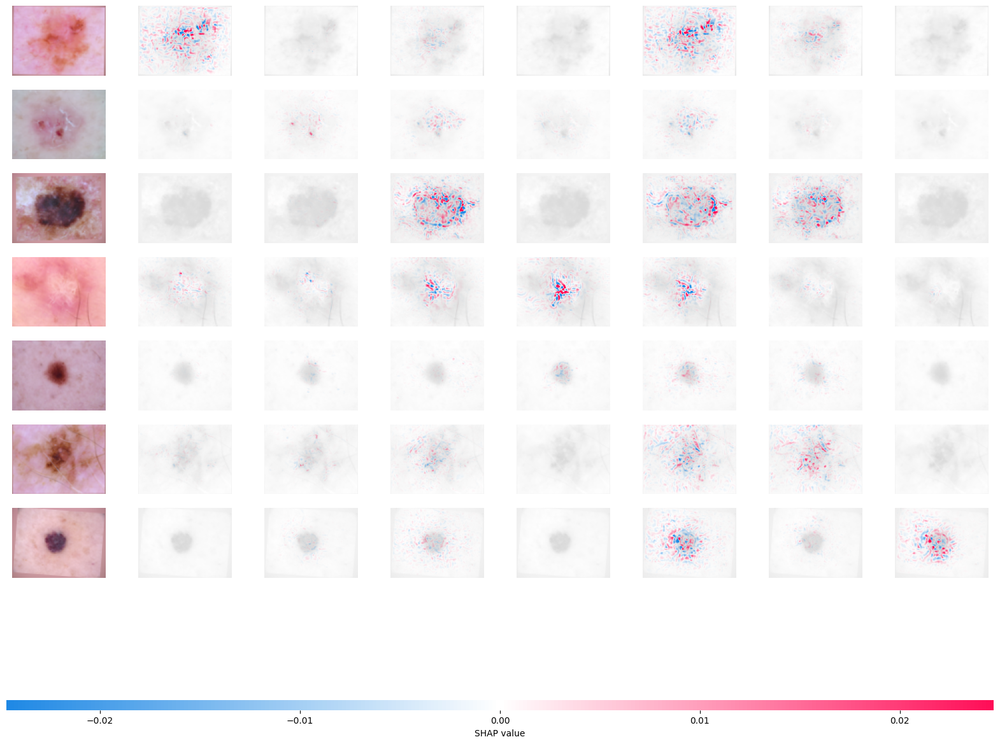

In [ ]:
# Plot reference column
plot_categories(images_dict)

# Print an empty line to separate the two plots
print()

# Plot shap values
shap.image_plot(shap_values, untransform_image(noisy_images))

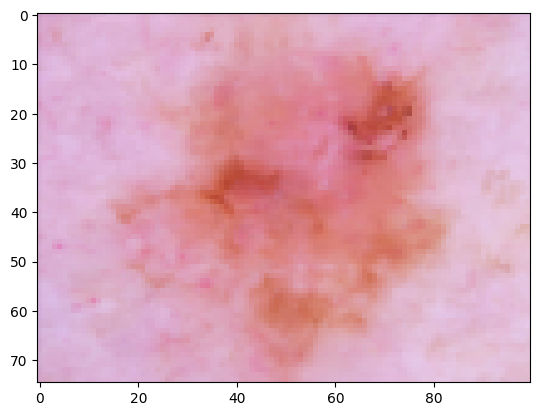

In [ ]:
plt.imshow(untransform_image(x_test_each_class_correct[0])[0])

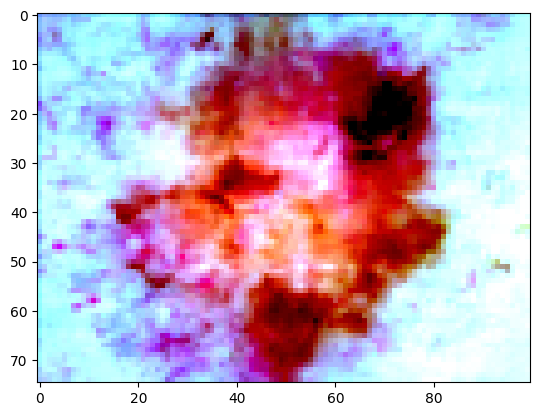

In [ ]:
plt.imshow(x_test_each_class_correct[0])

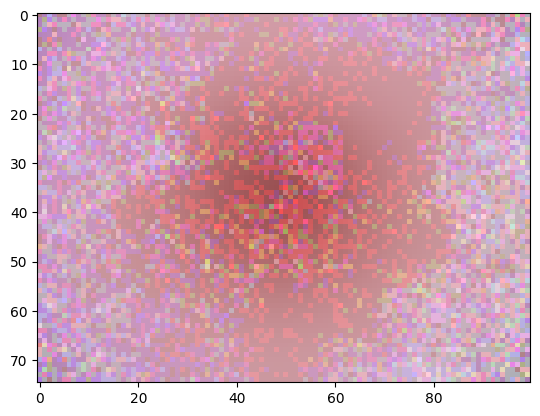

In [ ]:
plt.imshow(untransform_image(noisy_images[0])[0])

#### Augment

In [ ]:
!pip install imgaug --upgrade

In [ ]:
import imgaug as ia
from imgaug import augmenters as iaa

In [ ]:
affine_augmenter = iaa.Affine(scale=(0.9, 1.1), rotate=(-5, 5), shear=(-5, 5))  # Adjust ranges as needed

noisy_images = affine_augmenter.augment_images(x_test_each_class_correct)


ValueError: Got dtype 'float64', which is a forbidden dtype (uint32, uint64, uint128, uint256, int32, int64, int128, int256, float64, float96, float128, float256).

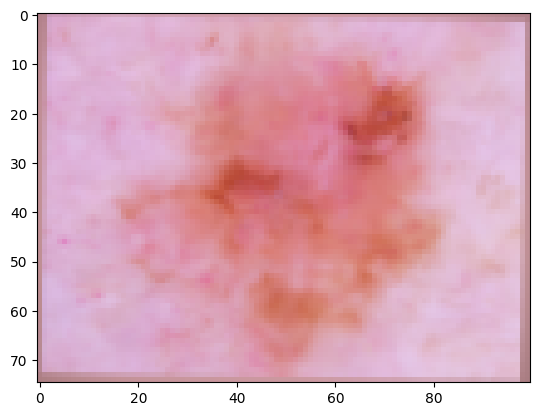

In [ ]:
plt.imshow(untransform_image(noisy_images[0])[0])

### Incorrectly predicted Shap Explanation

In [ ]:
%%time

shap_values = explain_with_shap(x_test_each_class_incorrect, VGG16model)

`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


CPU times: user 18.6 s, sys: 128 ms, total: 18.7 s
Wall time: 20.3 s


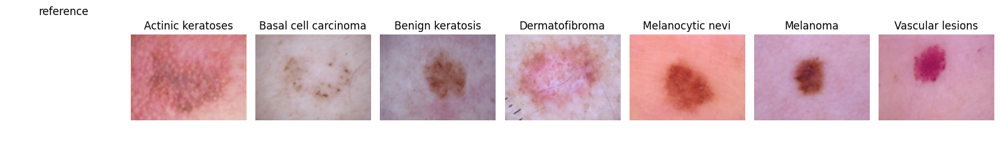

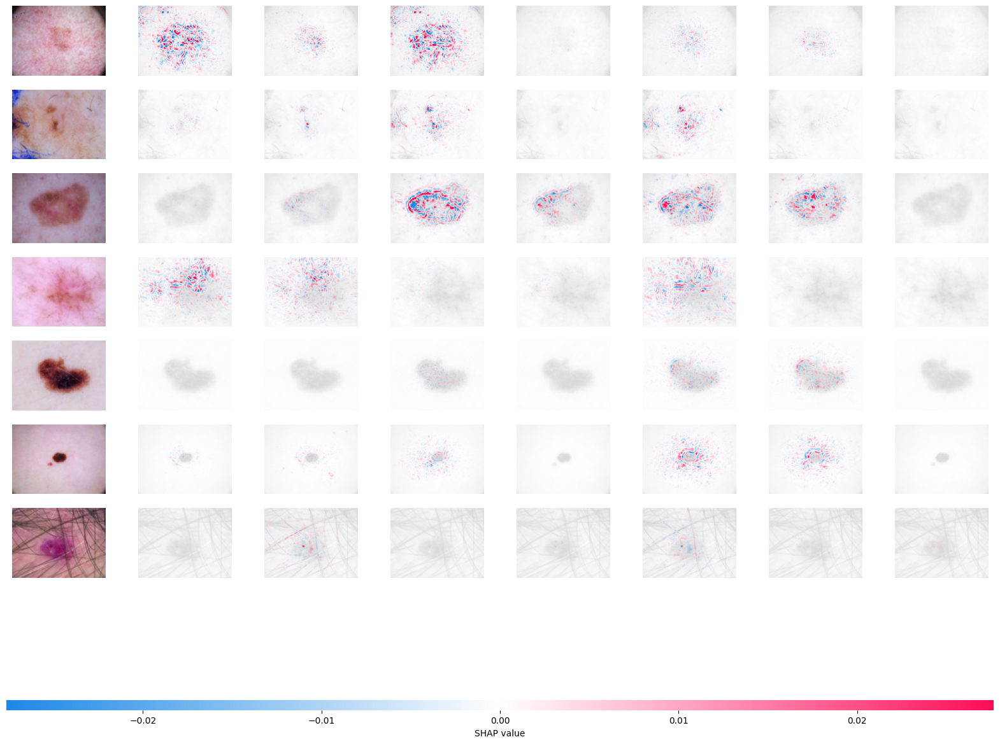

In [ ]:
# Plot reference column
plot_categories(images_dict)

# Print an empty line to separate the two plots
print()

# Plot shap values
shap.image_plot(shap_values, untransform_image(x_test_each_class_incorrect))

## LIME Explainations

In [ ]:
# ... LIME implementation ...
def explain_with_lime(images, model):
  """
  This function generates LIME explanations for a batch of images using the provided model.

  Args:
      images: A NumPy array of images (shape: (num_images, height, width, channels)).
      model: The model to use for generating predictions.

  Returns:
      A list of LIME explanation objects, one for each image in the batch.
  """
  explainer = lime_image.LimeImageExplainer(random_state=42)
  explanations = []
  for image in images:
    explanation = explainer.explain_instance(
        image, model.predict, top_labels=2
    )
    explanations.append(explanation)
  return explanations

In [ ]:
# Function to plot multiple explanations
def plot_explanations(images, explanations, central_title):
    """
    This function plots the original images and their LIME explanations highlighting important regions.

    Args:
        images: A list of original images (numpy arrays).
        explanations: A list of LIME explanation objects corresponding to the images.
    """
    num_images = len(images)
    fig = plt.figure(figsize=(15, 5 * num_images))
    fig.suptitle(central_title, fontsize=16)

    for i, (image, explanation) in enumerate(zip(images, explanations)):
        # Select the same class explained on the figures above.
        ind = explanation.top_labels[0]

        # Map each explanation weight to the corresponding superpixel
        dict_heatmap = dict(explanation.local_exp[ind])
        heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)

        im, mask = explanation.get_image_and_mask(ind, positive_only=True, hide_rest=True)

        # Plot original image
        plt.subplot(num_images, 3, i * 3 + 1)
        plt.imshow(untransform_image(image)[0])  # Assuming image is already preprocessed
        plt.title(f"{class_names_dict.get(ind)}")
        plt.axis("off")

        # Plot image with mask
        plt.subplot(num_images, 3, i * 3 + 2)
        plt.imshow(mark_boundaries(untransform_image(im)[0], mask))
        plt.title(f"LIME Explainer for class {ind}")
        plt.axis("off")

        # Plot heatmap
        plt.subplot(num_images, 3, i * 3 + 3)
        plt.imshow(heatmap, cmap='RdBu', vmin=-heatmap.max(), vmax=heatmap.max())
        plt.colorbar()
        plt.title("Heatmap Visualization")
        plt.axis("off")

    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

### Correctly predicted LIME Explanations

In [ ]:
%%time
# Get explanations for the correctly predicted images
explanations = explain_with_lime(x_test_each_class_correct, VGG16model)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 18ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 19ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

...

1/1 [==============================] - 0s 19ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 20ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 18ms/step
CPU times: user 1min 1s, sys: 1.87 s, total: 1min 3s
Wall time: 1min 14s


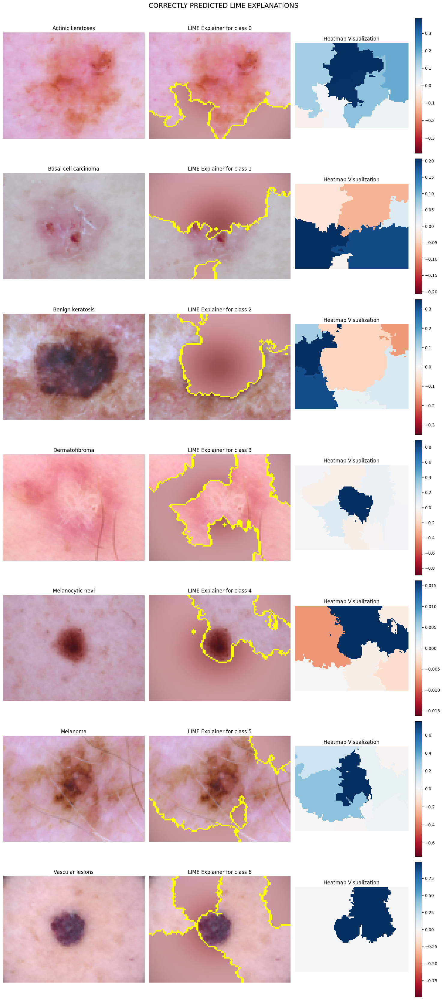

In [ ]:
# Plot the explanation using the defined function
plot_explanations(x_test_each_class_correct, explanations, 'CORRECTLY PREDICTED LIME EXPLANATIONS')

### Incorrectly predicted LIME Explanations

In [ ]:
%%time
# Get explanations for the correctly predicted images
explanations = explain_with_lime(x_test_each_class_incorrect, VGG16model)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 19ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 18ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

...

1/1 [==============================] - 0s 19ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 22ms/step


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 20ms/step
CPU times: user 1min 4s, sys: 1.91 s, total: 1min 6s
Wall time: 1min 27s


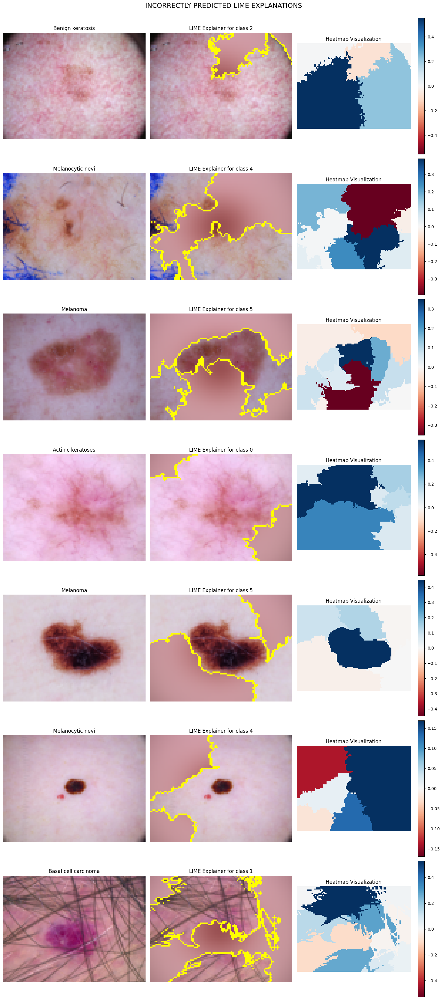

In [ ]:
# Plot the explanation using the defined function
plot_explanations(x_test_each_class_incorrect, explanations,'INCORRECTLY PREDICTED LIME EXPLANATIONS')

## Grad-CAM
Grad-CAM uses the gradients of the output class with respect to the feature maps of the last convolutional layer to produce a heatmap that highlights the important regions in the image for predicting the class.

In [ ]:
def grad_cam_func(model, original_image):
  """
  This function computes the Grad-CAM heatmap for a given image and model.

  Args:
      model: The Keras model to use for generating predictions and feature maps.
      original_image: The original image (numpy array) for which to generate the heatmap.

  Returns:
      The Grad-CAM heatmap as a numpy array.
  """

  # Preprocess the image (adjust as needed)
  img = np.expand_dims(original_image, axis=0)

  # Get the last convolutional layer name
  last_conv_layer_name = "block5_conv3"  # Adjust if necessary

  # Create a model that outputs both predictions and feature maps
  grad_model = keras.models.Model(
      [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
  )

  with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(img)
    # Get the index of the predicted class
    pred_index = np.argmax(predictions[0])
    # Get the score of the predicted class
    class_output = predictions[:, pred_index]

    # Get the gradient of the class output with respect to the feature maps
    grads = tape.gradient(class_output, conv_outputs)

    # Get the mean gradient for each feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Calculate the heatmap
    last_conv_layer_output = conv_outputs[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    # Convert the heatmap to numpy array
    heatmap = heatmap.numpy()

    # Resize the heatmap to match the original image size
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[2]))
    # Convert the heatmap to BGR color space
    # heatmap = cv2.cvtColor(heatmap, cv2.COLOR_RGB2BGR)
    # Convert the heatmap to BGR color space
    heatmap = cv2.applyColorMap((heatmap * 255).astype(np.uint8), cv2.COLORMAP_JET)

    # Ensure heatmap and image have the same number of channels (3 for RGB)
    if len(heatmap.shape) == 2:
        heatmap = np.expand_dims(heatmap, axis=2)

    # Resize heatmap to match the first two dimensions of image
    heatmap = cv2.resize(heatmap, (img[0].shape[1], img[0].shape[0]))  # Note the swapped order

    # Convert heatmap to float64 to match img[0]
    heatmap = heatmap.astype(img[0].dtype)

    # Superimpose the heatmap on the original image
    superimposed_img = cv2.addWeighted(untransform_image(img[0])[0], 0.6, heatmap, 2e-3, 0)

    # Return the heatmap
    return heatmap, superimposed_img, pred_index

In [ ]:
def plot_grad_cam_heatmaps(model, images, central_title):
    """
    This function plots the original images and their corresponding Grad-CAM heatmaps.

    Args:
        model: The neural network model.
        images: A list of original images (numpy arrays).
    """
    num_images = len(images)
    fig = plt.figure(figsize=(10, 3 * num_images))
    fig.suptitle(central_title, fontsize=16)

    for i, image in enumerate(images):
        heatmap, superimposed_img, pred_index = grad_cam_func(model, image)

        # Plot original image
        plt.subplot(num_images, 2, i * 2 + 1)
        plt.imshow(untransform_image(image)[0])
        plt.title(f"{class_names_dict[pred_index]}")
        plt.axis("off")

        # Plot Grad-CAM heatmap
        plt.subplot(num_images, 2, i * 2 + 2)
        plt.imshow(superimposed_img)
        plt.title(f"Grad-CAM Heatmap for class {pred_index}")
        plt.axis("off")

    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

### Correctly predicted Grad-CAM Explanations

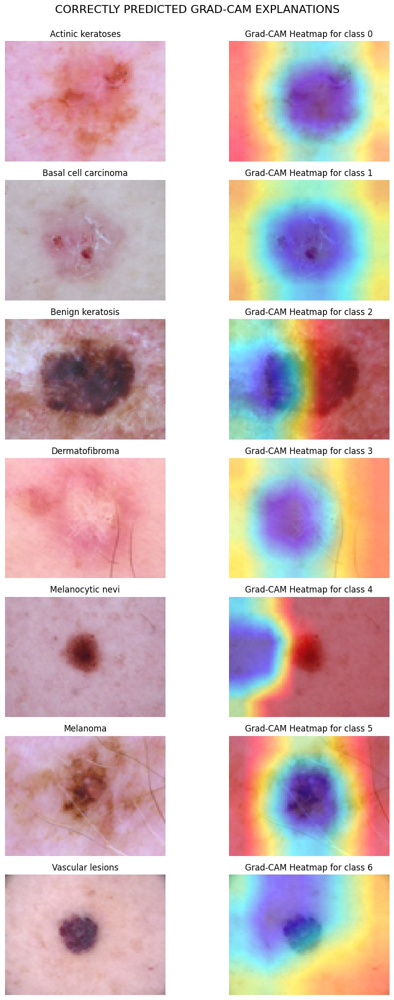

CPU times: user 2.21 s, sys: 84.7 ms, total: 2.3 s
Wall time: 4.58 s


In [ ]:
%%time
plot_grad_cam_heatmaps(VGG16model, x_test_each_class_correct, 'CORRECTLY PREDICTED GRAD-CAM EXPLANATIONS')

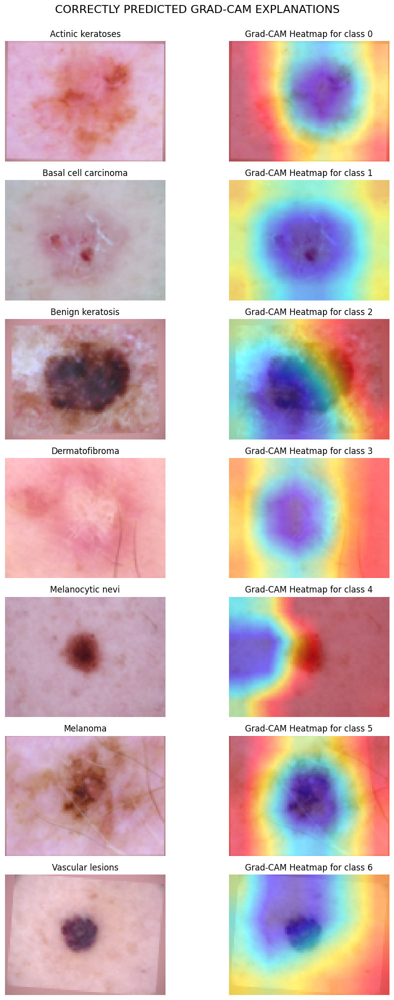

CPU times: user 4.52 s, sys: 202 ms, total: 4.72 s
Wall time: 5.89 s


In [ ]:
%%time
plot_grad_cam_heatmaps(VGG16model, noisy_images, 'CORRECTLY PREDICTED GRAD-CAM EXPLANATIONS')

### Incorrectly predicted Grad-CAM Explanations

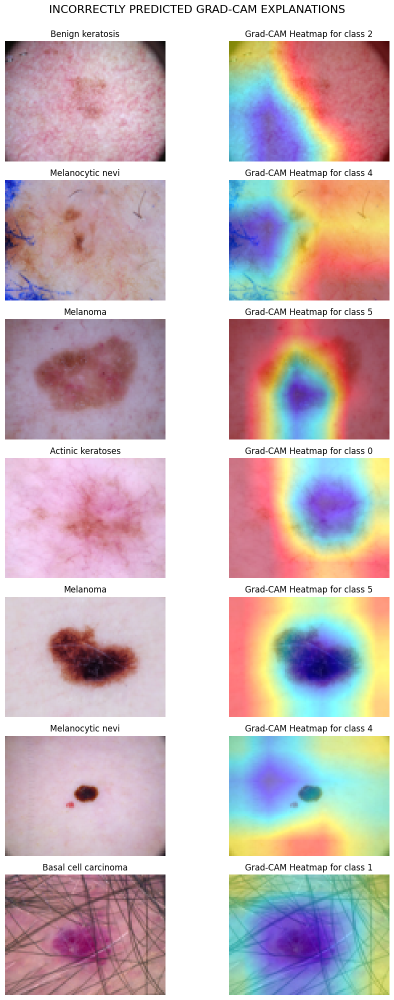

CPU times: user 2.3 s, sys: 128 ms, total: 2.43 s
Wall time: 2.67 s


In [ ]:
%%time
plot_grad_cam_heatmaps(VGG16model, x_test_each_class_incorrect, 'INCORRECTLY PREDICTED GRAD-CAM EXPLANATIONS')

### Stability Evaluation of Grad-CAM

In [ ]:
!pip install --upgrade scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.7/14.7 MB 29.2 MB/s eta 0:00:00
  Attempting uninstall: scikit-image
    Found existing installation: scikit-image 0.19.3
    Uninstalling scikit-image-0.19.3:
      Successfully uninstalled scikit-image-0.19.3


In [ ]:
# from skimage.metrics import iou
from skimage.metrics import __all__
print(__all__)


['adapted_rand_error', 'variation_of_information', 'contingency_table', 'mean_squared_error', 'normalized_mutual_information', 'normalized_root_mse', 'peak_signal_noise_ratio', 'structural_similarity', 'hausdorff_distance', 'hausdorff_pair']


In [ ]:
def calculate_iou(heatmap1, heatmap2):
  """
  Calculates the Intersection over Union (IoU) between two heatmaps.

  Args:
      heatmap1: First heatmap (numpy array).
      heatmap2: Second heatmap (numpy array).

  Returns:
      float: IOU score between the two heatmaps.
  """
  intersection = np.logical_and(heatmap1 > 0, heatmap2 > 0).sum()
  union = np.logical_or(heatmap1 > 0, heatmap2 > 0).sum()
  iou_score = intersection / float(union + 1e-6)  # Avoid division by zero
  return iou_score

def evaluate_stability(model, grad_cam_func, original_image, num_perturbations=10, noise_std=0.1):
  """
  Evaluates the stability of Grad-CAM by introducing noise perturbations.

  Args:
      model: The model to use for predictions.
      grad_cam_func: Function to generate Grad-CAM heatmaps.
      original_image: The original image (numpy array).
      num_perturbations: Number of noise perturbations to introduce.
      noise_std: Standard deviation of the Gaussian noise added.

  Returns:
      list: List of IoU scores between the original heatmap and perturbed heatmaps.
  """
  original_heatmap,_,_= grad_cam_func(model, original_image)

  iou_scores = []
  for _ in range(num_perturbations):
    perturbed_image = original_image.copy() + np.random.normal(0, noise_std, original_image.shape)
    perturbed_heatmap,_,_ = grad_cam_func(model, perturbed_image)
    iou_score = calculate_iou(original_heatmap, perturbed_heatmap)
    iou_scores.append(iou_score)

  return iou_scores

# Example usage (replace with your model and grad_cam function)
model = model # Your model
grad_cam_func = grad_cam_func # Function to generate Grad-CAM heatmaps
original_image = x_test[0] # Load your image

iou_scores = evaluate_stability(model, grad_cam_func, original_image)

# Analyze IoU scores
print("Average IoU:", np.mean(iou_scores))
print("Standard deviation:", np.std(iou_scores))

# Higher average IoU and lower standard deviation indicate better stability.


Average IoU: 0.964015151454292
Standard deviation: 0.03598484848257666


### Fidelity evaluation for Grad-CAM using occlusion sensitivity

In [ ]:
def evaluate_fidelity(model, image, grad_cam_func, occlusion_size=32):
  """
  Evaluates the fidelity of Grad-CAM using occlusion sensitivity.

  Args:
      model: The model to use for predictions.
      image: The original image (numpy array).
      grad_cam_func: Function to generate Grad-CAM heatmaps.
      occlusion_size: Size of the square occlusion window.

  Returns:
      float: Average drop in prediction confidence due to occlusion.
  """
  original_prediction = model.predict(np.expand_dims(image, axis=0))[0]
  original_heatmap,_,_ = grad_cam_func(model, image)

  # Initialize variables
  total_drop = 0
  num_occlusions = 0

  # Loop through different positions of the occlusion window
  for y in range(0, image.shape[0] - occlusion_size + 1, occlusion_size):
    for x in range(0, image.shape[1] - occlusion_size + 1, occlusion_size):
      occluded_image = image.copy()
      occluded_image[y:y+occlusion_size, x:x+occlusion_size] = 0  # Occlude the region

      occluded_prediction = model.predict(np.expand_dims(occluded_image, axis=0))[0]
      drop_in_confidence = abs(original_prediction - occluded_prediction)

      total_drop += drop_in_confidence
      num_occlusions += 1

  # Average drop in confidence across all occlusions
  average_drop = total_drop / num_occlusions

  return average_drop

# Example usage (replace with your model and grad_cam function)
model = model # Your model
grad_cam_func = grad_cam_func # Function to generate Grad-CAM heatmaps
image = x_test[0] # Load your image

average_drop = evaluate_fidelity(model, image, grad_cam_func)

# Higher average drop suggests the model relies more on the occluded regions
# for its prediction, indicating potential fidelity.
print("Average drop in confidence:", average_drop)


1/1 [==============================] - 0s 17ms/step
Average drop in confidence: [7.4505596e-03 5.2546537e-01 3.9536622e-03 5.8109063e-01 7.3993504e-02
 5.2618579e-04 1.5366447e-04]


In [ ]:
model.predict(np.expand_dims(x_test[0], axis=0))[0]

1/1 [==============================] - 0s 35ms/step


array([2.76903738e-04, 6.72082841e-01, 2.54537608e-03, 2.14723319e-01,
       1.09731644e-01, 4.59113100e-04, 1.80831092e-04], dtype=float32)